# Week 2: Linear Regression Exercise - Bruno Cavagnaro (Python version)


This notebook solves the GRAD 508 Week 2 exercise in Python instead of R. The R functions map to Python as follows: `read.csv()` → `pandas.read_excel()` / `read_csv()`, `plot()` → `matplotlib`, and `lm()` + `summary()` → `statsmodels.formula.api.ols()` + `.summary()`.

## Steps 1–2: Set the working directory and read in the data

In [3]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.model_selection import LeaveOneOut

df = pd.read_excel("data/height_data_fake.xlsx")

df

,Height_birth_feet,Biological_sex,Age_months,Height_feet,Weight_pounds
0,0.80,M,1,1.0,8.0
1,0.50,F,1,0.9,7.0
2,0.90,M,1,1.2,8.5
3,0.70,F,2,1.0,9.0
4,1.00,M,2,1.3,11.0
5,1.20,M,2,1.4,12.0
6,0.60,F,3,1.0,12.0
7,0.50,F,3,0.9,13.0
8,0.80,M,3,1.4,14.0
9,0.90,F,4,1.4,15.0


In [4]:
df.info()
df.describe(include="all")

<class 'pandas.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Height_birth_feet  19 non-null     float64
 1   Biological_sex     19 non-null     str    
 2   Age_months         19 non-null     int64  
 3   Height_feet        19 non-null     float64
 4   Weight_pounds      19 non-null     float64
dtypes: float64(3), int64(1), str(1)
memory usage: 892.0 bytes


,Height_birth_feet,Biological_sex,Age_months,Height_feet,Weight_pounds
count,19.000000,19,19.000000,19.000000,19.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,F,NaN,NaN,NaN
freq,NaN,10,NaN,NaN,NaN
mean,0.826316,NaN,2.894737,1.268421,12.078947
std,0.189567,NaN,1.410072,0.266776,3.536568
min,0.500000,NaN,1.000000,0.900000,7.000000
25%,0.675000,NaN,2.000000,1.000000,8.750000
50%,0.900000,NaN,3.000000,1.300000,12.000000
75%,0.950000,NaN,4.000000,1.450000,15.000000


**Data note.** The dataset has 19 children and 5 variables: height at birth (feet), biological sex (M/F), age (months), current height (feet) and weight (pounds). The last row has a weight of 1121 lb, which is clearly a data-entry error (probably meant to be about 11). Weight is not used in any of the models below, so this outlier does not affect the results, but it is worth flagging.

## Step 3: Plot age against height

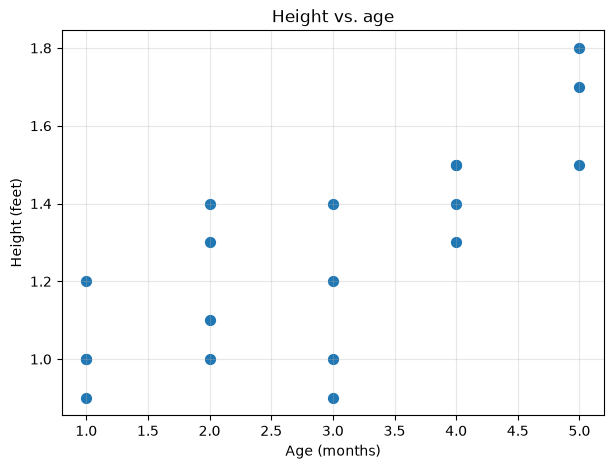

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["Age_months"], df["Height_feet"], s=50)
ax.set_xlabel("Age (months)")
ax.set_ylabel("Height (feet)")
ax.set_title("Height vs. age")
ax.grid(alpha=0.3)
plt.show()

The plot shows a clear positive, roughly linear relationship: older children are taller. There is noticeable vertical spread at each age (for example, at 3 months heights range from 0.9 to 1.4 ft), which suggests other variables also explain height.

## Step 4: Simple linear regression — `Height_feet ~ Age_months`

In [6]:
model_simple = smf.ols("Height_feet ~ Age_months", data=df).fit()
print(model_simple.summary())

                            OLS Regression Results                            
Dep. Variable:            Height_feet   R-squared:                       0.598
Model:                            OLS   Adj. R-squared:                  0.575
Method:                 Least Squares   F-statistic:                     25.31
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           0.000103
Time:                        12:42:01   Log-Likelihood:                 7.3205
No. Observations:                  19   AIC:                            -10.64
Df Residuals:                      17   BIC:                            -8.752
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.8449      0.093      9.066      0.0

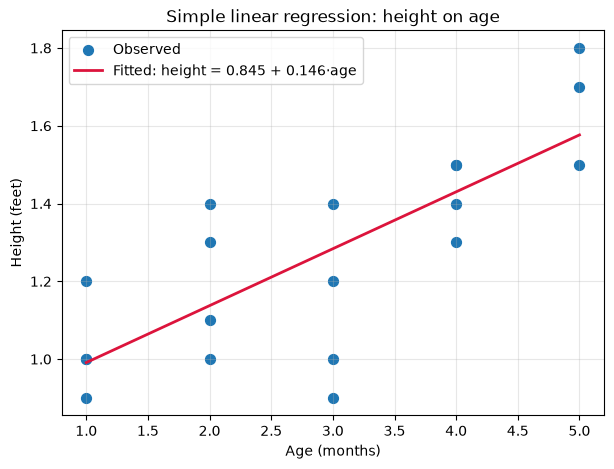

In [7]:
# Scatter plot with fitted regression line (like abline(lm(...)) in R)
x_grid = np.linspace(df["Age_months"].min(), df["Age_months"].max(), 100)
y_hat = model_simple.params["Intercept"] + model_simple.params["Age_months"] * x_grid

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["Age_months"], df["Height_feet"], s=50, label="Observed")
ax.plot(x_grid, y_hat, color="crimson", lw=2,
        label=f"Fitted: height = {model_simple.params['Intercept']:.3f} + {model_simple.params['Age_months']:.3f}·age")
ax.set_xlabel("Age (months)")
ax.set_ylabel("Height (feet)")
ax.set_title("Simple linear regression: height on age")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

The fitted equation is **height = 0.845 + 0.146 × age**. Each additional month of age is associated with about 0.146 ft (≈1.76 inches) more height, and the slope is highly significant (p ≈ 0.0001). Age alone explains about 60% of the variance in height (R² = 0.598).

## Step 5: Multiple linear regression — `Height_feet ~ Age_months + Biological_sex + Height_birth_feet`

In [8]:
# C() treats sex as categorical, exactly like a factor in R.
# Female (F) is the reference level by default (alphabetical), same as R.
model_multi = smf.ols(
    "Height_feet ~ Age_months + C(Biological_sex) + Height_birth_feet",
    data=df
).fit()
print(model_multi.summary())

                            OLS Regression Results                            
Dep. Variable:            Height_feet   R-squared:                       0.904
Model:                            OLS   Adj. R-squared:                  0.884
Method:                 Least Squares   F-statistic:                     46.93
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           7.38e-08
Time:                        12:45:01   Log-Likelihood:                 20.894
No. Observations:                  19   AIC:                            -33.79
Df Residuals:                      15   BIC:                            -30.01
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  0

In [9]:
# Compact coefficient table
coef_table = pd.DataFrame({
    "Estimate": model_multi.params,
    "Std. Error": model_multi.bse,
    "t value": model_multi.tvalues,
    "p value": model_multi.pvalues,
    "CI 2.5%": model_multi.conf_int()[0],
    "CI 97.5%": model_multi.conf_int()[1],
}).round(4)
coef_table

,Estimate,Std. Error,t value,p value,CI 2.5%,CI 97.5%
Intercept,0.3215,0.0986,3.2590,0.0053,0.1112,0.5317
C(Biological_sex)[T.M],0.1047,0.0459,2.2813,0.0376,0.0069,0.2026
Age_months,0.1280,0.0160,8.0169,0.0000,0.0940,0.1620
Height_birth_feet,0.6376,0.1279,4.9856,0.0002,0.3650,0.9102


## Step 6: Interpretation of the multiple regression model

The fitted model is:

$$\widehat{\text{Height}} = 0.322 + 0.128\,\text{Age} + 0.105\,\text{Male} + 0.638\,\text{BirthHeight}$$

Each coefficient is interpreted *holding the other predictors constant*.

**Age (β = 0.128, p < 0.001).** For two children of the same sex and the same height at birth, each extra month of age is associated with about 0.128 ft (≈1.54 inches) more height. The 95% CI (0.094 to 0.162) is well away from zero, so there is very strong evidence of an age effect. The slope is a bit smaller than in the simple model (0.146) because part of what age appeared to explain on its own is now attributed to sex and birth height.

**Biological sex (β = 0.105 for M vs. F, p = 0.038).** Female is the reference group. Holding age and birth height fixed, boys are on average about 0.105 ft (≈1.26 inches) taller than girls. The p value is below 0.05, so the effect is statistically significant at the conventional 5% level, but it is the weakest of the three effects and the confidence interval (0.007 to 0.203) is wide, nearly touching zero. With only 19 observations this estimate should be treated with caution.

**Height at birth (β = 0.638, p < 0.001).** For children of the same age and sex, each additional foot of birth height is associated with 0.638 ft more current height. Since birth heights range only from 0.5 to 1.2 ft, a more practical reading is that each extra 0.1 ft at birth corresponds to about 0.064 ft (≈0.77 inches) more current height. The evidence is very strong.

**Intercept (β = 0.322, p = 0.005).** This is the predicted height of a girl aged 0 months with a birth height of 0 ft. That combination is impossible, so the intercept has no meaningful interpretation here; it simply anchors the regression plane.

**What the p values mean.** Each p value tests the null hypothesis that the coefficient equals zero given the other predictors are in the model. A small p value means data like ours would be very unlikely if that predictor truly had no effect. The overall F-test (F = 46.9, p ≈ 7×10⁻⁸) tests whether all three slopes are zero at once, and that hypothesis is clearly rejected.

**Fit.** The model explains about 90% of the variance in height (R² = 0.904, adjusted R² = 0.884), compared with 60% for age alone.

## Step 7: Classification or regression?

It is a **regression** model. The outcome, height in feet, is a continuous numeric variable, and the model predicts a numeric value for it. A classification model would predict a categorical label (for example, whether a child is "tall" or "not tall", or their biological sex). The fact that one *predictor* (sex) is categorical does not matter; the type of model is determined by the outcome variable.

## Step 8: Simple or multiple regression?

It is a **multiple** linear regression model because it uses three predictors (age, biological sex and height at birth) to explain one outcome. A simple linear regression has exactly one predictor, like the model in Step 4.

## Step 9: Supervised or unsupervised learning?

Linear regression is **supervised** learning. The training data contains the true value of the outcome (height) for every observation, and the model learns the mapping from inputs to that known output by minimizing the squared difference between predicted and observed heights. Unsupervised learning (such as clustering or PCA) has no outcome variable and instead looks for structure among the inputs alone.

## Step 10: Metrics used to evaluate the models

In [10]:
def loocv_rmse(formula, data):
    """Leave-one-out cross-validated RMSE: refit n times, each time predicting the held-out child."""
    errs = []
    for train_idx, test_idx in LeaveOneOut().split(data):
        train, test = data.iloc[train_idx], data.iloc[test_idx]
        fit = smf.ols(formula, data=train).fit()
        errs.append(test["Height_feet"].values[0] - fit.predict(test).values[0])
    return np.sqrt(np.mean(np.square(errs)))

def metrics(model, formula):
    return {
        "R²": model.rsquared,
        "Adjusted R²": model.rsquared_adj,
        "Residual std. error (ft)": np.sqrt(model.mse_resid),
        "In-sample RMSE (ft)": np.sqrt(np.mean(model.resid**2)),
        "LOOCV RMSE (ft)": loocv_rmse(formula, df),
        "F-statistic": model.fvalue,
        "F-test p value": model.f_pvalue,
        "AIC": model.aic,
        "BIC": model.bic,
    }

f1 = "Height_feet ~ Age_months"
f2 = "Height_feet ~ Age_months + C(Biological_sex) + Height_birth_feet"
comparison = pd.DataFrame({
    "Simple (age only)": metrics(model_simple, f1),
    "Multiple (age + sex + birth height)": metrics(model_multi, f2),
})
comparison.style.format("{:.4g}")

,Simple (age only),Multiple (age + sex + birth height)
R²,0.5982,0.9037
Adjusted R²,0.5745,0.8845
Residual std. error (ft),0.174,0.09068
In-sample RMSE (ft),0.1646,0.08057
LOOCV RMSE (ft),0.181,0.1044
F-statistic,25.31,46.93
F-test p value,0.0001028,7.379e-08
AIC,-10.64,-33.79
BIC,-8.752,-30.01


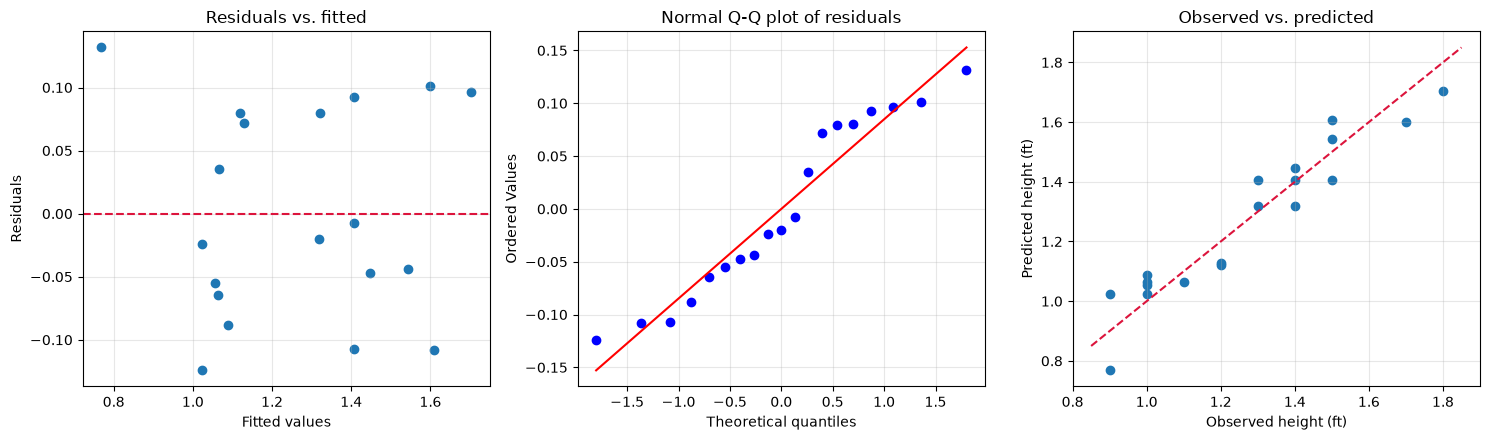

In [11]:
# Residual diagnostics for the multiple model
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].scatter(model_multi.fittedvalues, model_multi.resid)
axes[0].axhline(0, color="crimson", ls="--")
axes[0].set(xlabel="Fitted values", ylabel="Residuals", title="Residuals vs. fitted")

import scipy.stats as st
st.probplot(model_multi.resid, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q plot of residuals")

axes[2].scatter(df["Height_feet"], model_multi.fittedvalues)
lims = [df["Height_feet"].min() - 0.05, df["Height_feet"].max() + 0.05]
axes[2].plot(lims, lims, color="crimson", ls="--")
axes[2].set(xlabel="Observed height (ft)", ylabel="Predicted height (ft)", title="Observed vs. predicted")

for a in axes: a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Which metrics and why.**

**R² and adjusted R².** R² is the share of variance in height explained by the model (0.598 → 0.904). Because R² can only go up when predictors are added, I also used adjusted R², which penalizes extra predictors. It also rises substantially (0.575 → 0.884), so the improvement is real and not just a side effect of adding variables.

**Residual standard error / RMSE.** This measures the typical prediction error in the units of the outcome, which makes it easy to interpret. It drops from about 0.17 ft (≈2.1 in) to about 0.09 ft (≈1.1 in).

**Leave-one-out cross-validated RMSE.** All the metrics above are computed on the same data used to fit the model, so they can be optimistic. With only 19 observations a train/test split would leave too little data, so LOOCV is the sensible way to estimate out-of-sample error. The multiple model still has clearly lower LOOCV RMSE, which indicates it generalizes better and is not just overfitting.

**F-test and coefficient p values.** These answer whether the model (and each predictor) explains more than chance would. Both models are highly significant overall.

**AIC/BIC.** These trade off fit against complexity; lower is better. Both are much lower for the multiple model, confirming it as the preferred model.

**Residual plots.** Metrics alone don't check the regression assumptions. The residuals-vs-fitted plot shows no obvious pattern or funnel shape, and the Q-Q plot is reasonably close to the line, so linearity, constant variance and approximate normality look acceptable, keeping in mind that 19 points is too few to assess these firmly.

**Conclusion:** adding biological sex and height at birth substantially improves the model on every metric, in-sample and out-of-sample.